# CE 463 — Digital Signal and Image Processing

## Assignment 1: Setting Up Jupyter Notebook and Running Image Processing Examples


**Student Name:** Adombire George Gyan Kwame
**Student ID:** SRI.41.008.010.23
**Environment:** Python(image_proc_env)    

## Example 1: Working with Grayscale Images

**Reference:** Section 7.2, pages 83-84


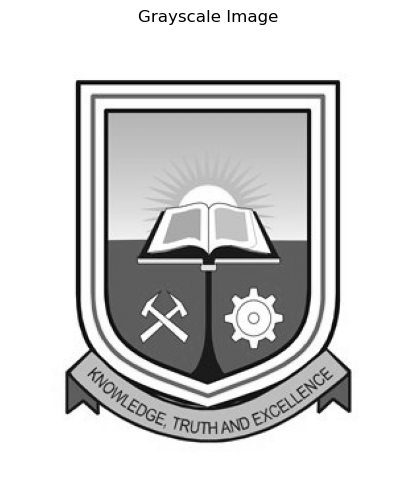

Image shape (Height x Width): (350, 300)
Pixel values range from 0 to 255


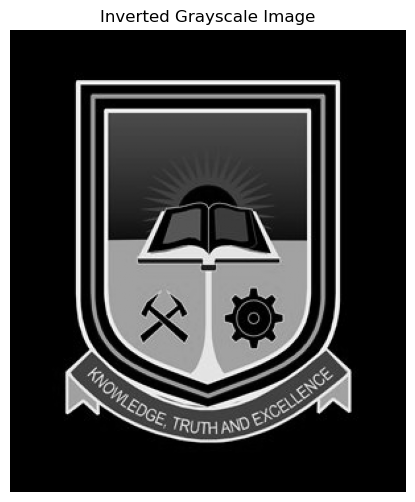

In [2]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load an image and convert it to grayscale
image = Image.open('sample_image.jpg').convert('L')

# Display the grayscale image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()

# Convert the image to a NumPy array (pixel array)
image_array = np.array(image)

# Print basic information about the image
print(f"Image shape (Height x Width): {image_array.shape}")
print(f"Pixel values range from {image_array.min()} to {image_array.max()}")

# Modify the image: Invert the colors (255 - pixel value)
inverted_image_array = 255 - image_array

# Convert back to an image and display it
inverted_image = Image.fromarray(inverted_image_array)
plt.figure(figsize=(6, 6))
plt.imshow(inverted_image, cmap='gray')
plt.title('Inverted Grayscale Image')
plt.axis('off')
plt.show()

**Explanation:**

This code opens `sample_image.jpg` and converts it into an 8-bit grayscale image, where each pixel represents a brightness level. NumPy converts the image into an array so we can inspect its dimensions and pixel intensity range. The expression `255 - image_array` inverts the pixel values, making dark areas light and light areas dark. The resulting image looks like a photographic negative of the original image.

   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
    --------------------------------------- 0.3/12.8 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.8 MB 1.4 MB/s eta 0:00:09
   --- ------------------------------------ 1.0/12.8 MB 2.2 MB/s eta 0:00:06
   ---- ----------------------------------- 1.6/12.8 MB 2.2 MB/s eta 0:00:06
   ----- ---------------------------------- 1.8/12.8 MB 2.4 MB/s eta 0:00:05
   -------- ------------------------------- 2.6/12.8 MB 2.3 MB/s eta 0:00:05
   -------- ------------------------------- 2.6/12.8 MB 2.3 MB/s eta 0:00:05
   --------- ------------------------------ 3.1/12.8 MB 2.1 MB/s eta 0:00:05
   ----------- ---------------------------- 3.7/12.8 MB 2.0 MB/s eta 0:00:05
   ------------- -------------------------- 4.2/12.8 MB 2.1 MB/s eta 0:00:05
   ------------- -------------------------- 4.5/12.8 MB 2.0 MB/s eta 0:00:05
   --------------- ------------------------ 5.0/12.8 MB 2.1 MB/s eta 0:00:04
   ----------

## Example 2: Image Sampling and Downsampling

**Reference:** Section 7.4.1, page 85

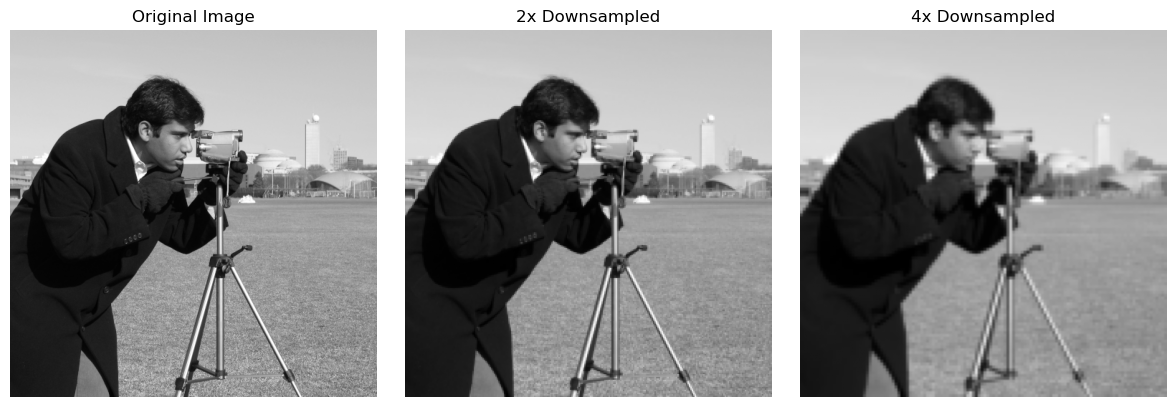

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, transform

# Load an example image
image = data.camera()

# Downsample the image by different factors (simulate lower sampling rates)
sampled_image_2x = transform.rescale(
    image, 0.5, anti_aliasing=True
)  # Downsample by 2x

sampled_image_4x = transform.rescale(
    image, 0.25, anti_aliasing=True
)  # Downsample by 4x

# Display original and downsampled images
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')

axes[1].imshow(sampled_image_2x, cmap='gray')
axes[1].set_title('2x Downsampled')

axes[2].imshow(sampled_image_4x, cmap='gray')
axes[2].set_title('4x Downsampled')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

**Explanation:**

This example demonstrates image sampling by reducing the resolution of a grayscale image. The original image is downsampled by factors of two and four using `transform.rescale()`. The 2x downsampled image has half the original height and width, while the 4x downsampled image has one-quarter of the original height and width. As the sampling rate decreases, fewer pixels represent the image, which can cause some fine details to be lost.

## Example 3: Image Quantization at Different Bit Depths

**Reference:** Section 7.4.2, pages 86–87

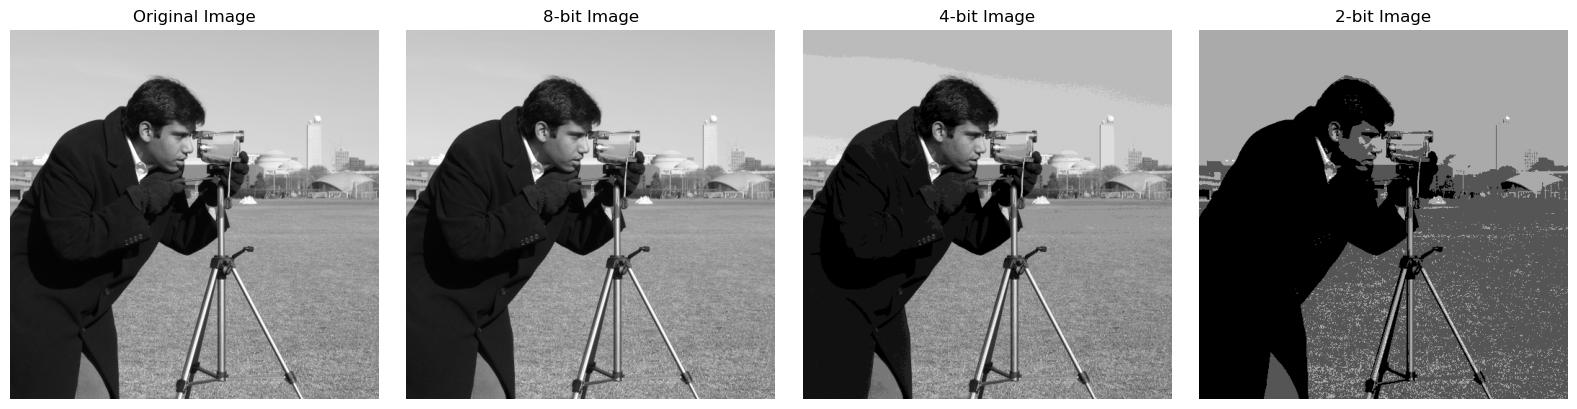

In [8]:
# Function to quantize an image to a specified number of bits
def quantize_image(image, num_bits):
    max_val = 2**num_bits - 1
    quantized_image = np.floor(image / 255 * max_val)
    return (quantized_image / max_val) * 255

# Quantize the image to different bit depths
image_8bit = quantize_image(image, 8)  # 8-bit quantization
image_4bit = quantize_image(image, 4)  # 4-bit quantization
image_2bit = quantize_image(image, 2)  # 2-bit quantization

# Display original and quantized images
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Original Image')

axes[1].imshow(image_8bit, cmap='gray')
axes[1].set_title('8-bit Image')

axes[2].imshow(image_4bit, cmap='gray')
axes[2].set_title('4-bit Image')

axes[3].imshow(image_2bit, cmap='gray')
axes[3].set_title('2-bit Image')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

**Explanation:**

Image quantization reduces the number of intensity levels available to represent an image. The `quantize_image()` function maps pixel values to a specified number of levels based on the selected bit depth. An 8-bit image can represent 256 intensity levels, a 4-bit image can represent 16 levels, and a 2-bit image can represent only 4 levels. As the bit depth decreases, the image shows fewer shades of gray, making intensity transitions more noticeable and reducing the amount of detail represented.